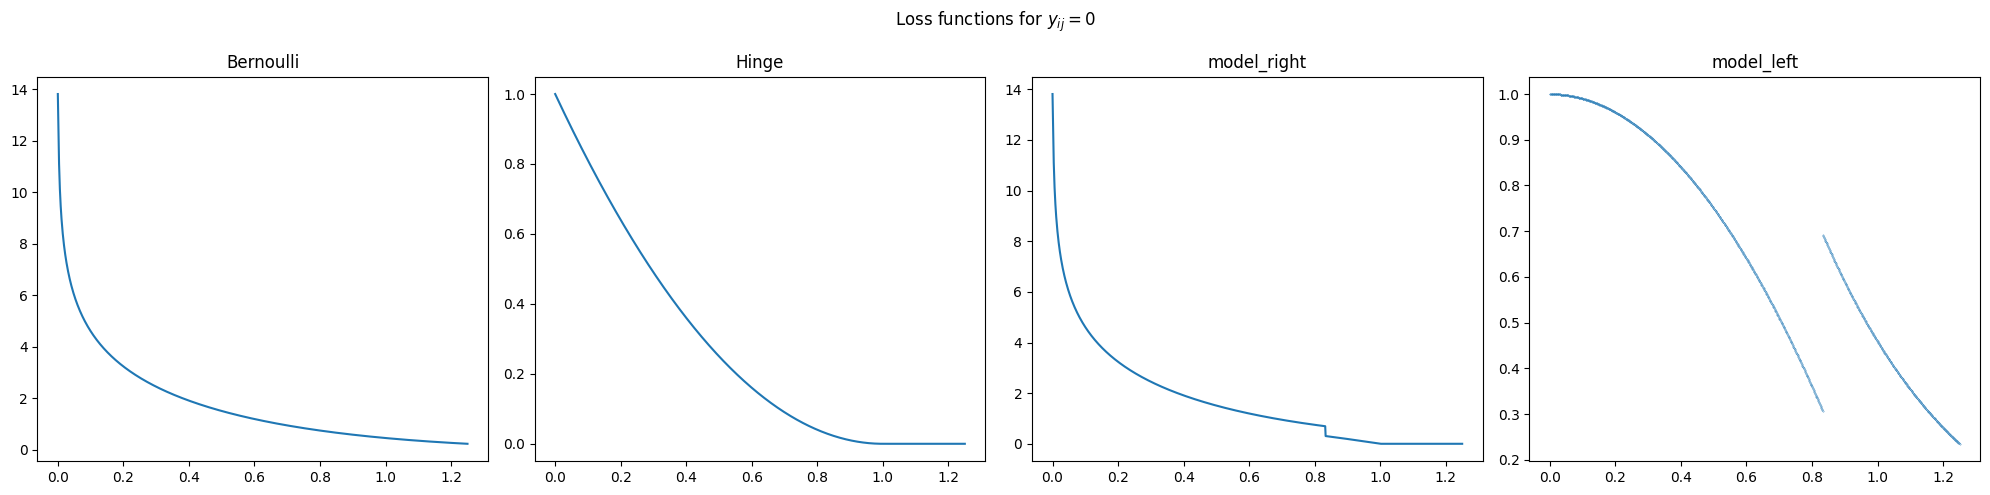

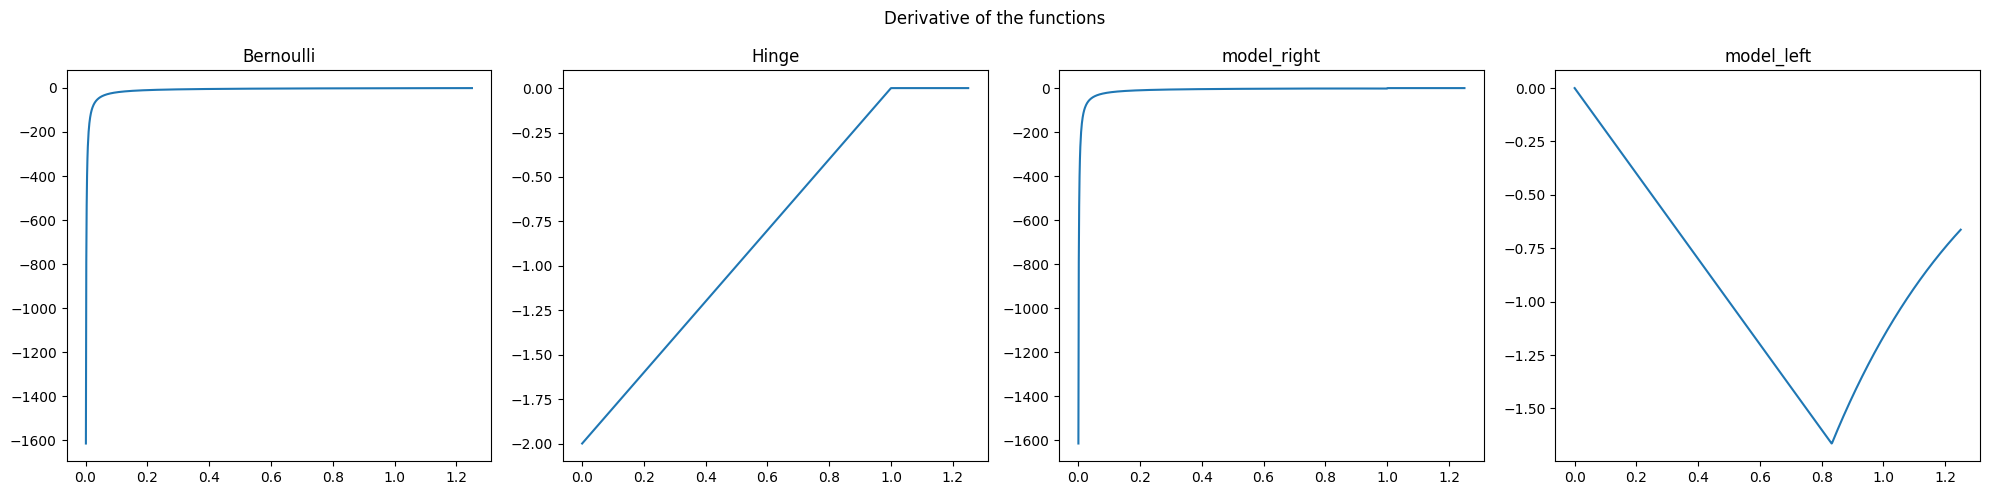

In [30]:
import torch
import matplotlib.pyplot as plt
from sympy import bernoulli

dist = torch.linspace(0, 1.25, 1000)

bernoulli = -torch.log(1 - torch.exp(-dist**2) + 1e-6)

hinge = torch.nn.functional.relu(1 - dist) ** 2

v5 = -torch.log(1 - torch.exp(-dist**2) + 1e-6)
idx = dist > torch.sqrt(torch.log(torch.asarray([2.])))
v5[idx] = torch.nn.functional.relu(1-dist[idx]**2)

v6 = -torch.log(1 - torch.exp(-dist**2) + 1e-6)
idx = dist <= torch.sqrt(torch.log(torch.asarray([2.])))
v6[idx] = 1-dist[idx]**2

# Plot 3 figures side by side
fig, ax = plt.subplots(1, 4, figsize=(20, 5))
fig.suptitle('Loss functions for $y_{ij}=0$')
ax[0].plot(dist, bernoulli, '-', label='Bernoulli', ms=0.5)
ax[0].set_title('Bernoulli')

ax[1].plot(dist, hinge, '-', label='Hinge', ms=0.5)
ax[1].set_title('Hinge')

ax[2].plot(dist, v5, ms=0.5)
ax[2].set_title('model_right')

ax[3].plot(dist, v6, '.', ms=0.5)
ax[3].set_title('model_left')
# plt.show()
plt.tight_layout()
plt.savefig('loss_comparisons.png')

# Derivatives: Plot 3 figures side by side

bernoulli = -(2*dist) / (torch.exp(dist**2) -1)

hinge = -2*torch.nn.functional.relu(1 - dist)

v5 = -(2*dist) / (torch.exp(dist**2) -1)
idx = dist > torch.sqrt(torch.log(torch.asarray([2.])))
v5[idx] = -2 * dist[idx]
v5[dist > 1] = 0 # this is because of the relu function

v6 = -(2*dist) / (torch.exp(dist**2) -1)
idx = dist <= torch.sqrt(torch.log(torch.asarray([2.])))
v6[idx] = -2*dist[idx]

fig, ax = plt.subplots(1, 4, figsize=(20, 5))
fig.suptitle('Derivative of the functions')

ax[0].plot(dist, bernoulli, '-', label='Bernoulli', )
ax[0].set_title('Bernoulli')

ax[1].plot(dist, hinge, '-', label='Hinge', )
ax[1].set_title('Hinge')

ax[2].plot(dist, v5, ms=0.5)
ax[2].set_title('model_right')

ax[3].plot(dist, v6, ms=0.5)
ax[3].set_title('model_left')
# plt.show()
plt.tight_layout()
plt.savefig('derivative_comparisons.png')